# Practical 9: Polynomial Regression – Underfitting and Overfitting

**Aim:** To implement Polynomial Regression on the Advertising dataset and demonstrate underfitting and overfitting.

**Dataset:** [Advertising Dataset on Kaggle](https://www.kaggle.com/datasets/yasserh/advertising-sales-dataset)

Download `Advertising.csv`, extract it, and keep it in the same folder as this notebook.

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

In [9]:
df = pd.read_csv("Advertising.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df.head()


,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [10]:
df.shape

(200, 4)

In [11]:
df.isna().sum()

TV Ad Budget ($)           0
Radio Ad Budget ($)        0
Newspaper Ad Budget ($)    0
Sales ($)                  0
dtype: int64

In [12]:
# Select input and output
feature_name = "TV Ad Budget ($)"
X = df[[feature_name]]
y = df["Sales ($)"]


In [13]:
X

,TV Ad Budget ($)
0,230.1
1,44.5
2,17.2
3,151.5
4,180.8
...,...
195,38.2
196,94.2
197,177.0
198,283.6


In [14]:
y

0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: Sales ($), Length: 200, dtype: float64

In [15]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [16]:
# Underfitting: polynomial degree 1
underfit = make_pipeline(
    PolynomialFeatures(degree=1),
    LinearRegression()
)

underfit.fit(X_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=1)),
                ('linearregression', LinearRegression())])

In [17]:
# Good fit: polynomial degree 2
good_fit = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

good_fit.fit(X_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

In [18]:
# Overfitting: high polynomial degree
overfit = make_pipeline(
    PolynomialFeatures(degree=5),
    LinearRegression()
)

overfit.fit(X_train, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=5)),
                ('linearregression', LinearRegression())])

In [19]:
# Check accuracy using R2
print("UNDERFITTING")
print("Training R2:", underfit.score(X_train, y_train))
print("Testing R2 :", underfit.score(X_test, y_test))

print("\nGOOD FIT")
print("Training R2:", good_fit.score(X_train, y_train))
print("Testing R2 :", good_fit.score(X_test, y_test))

print("\nOVERFITTING")
print("Training R2:", overfit.score(X_train, y_train))
print("Testing R2 :", overfit.score(X_test, y_test))

UNDERFITTING
Training R2: 0.5736021199591975
Testing R2 : 0.6714477229302764

GOOD FIT
Training R2: 0.589631403222505
Testing R2 : 0.6551656885746755

OVERFITTING
Training R2: 0.6021914219657342
Testing R2 : 0.655110778850537


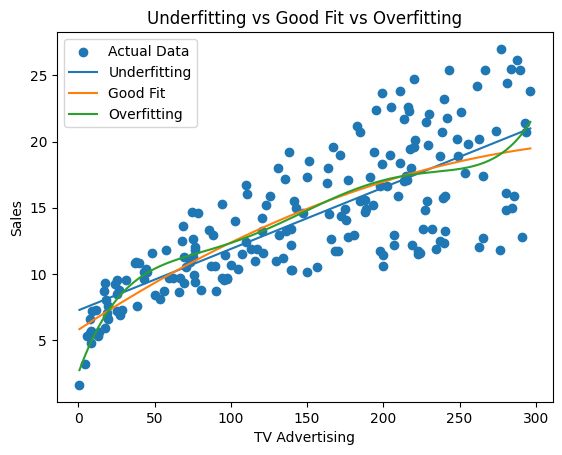

In [20]:
# Create points for smooth curves
X_plot = pd.DataFrame({
    feature_name: np.linspace(
        X[feature_name].min(),
        X[feature_name].max(),
        300
    )
})

# Predictions
y_under = underfit.predict(X_plot)
y_good = good_fit.predict(X_plot)
y_over = overfit.predict(X_plot)

# Plot actual data
plt.scatter(X[feature_name], y, label="Actual Data")

# Plot models
plt.plot(X_plot[feature_name], y_under, label="Underfitting")
plt.plot(X_plot[feature_name], y_good, label="Good Fit")
plt.plot(X_plot[feature_name], y_over, label="Overfitting")

plt.xlabel("TV Advertising")
plt.ylabel("Sales")
plt.title("Underfitting vs Good Fit vs Overfitting")
plt.legend()
plt.show()


## Conclusion

Polynomial Regression was implemented on the Advertising dataset using TV advertising as input and Sales as output. Models of different polynomial degrees were compared using training and testing R² scores to demonstrate underfitting, good fit, and overfitting.